In [1]:
import sys

print(sys.executable)

c:\Users\diego\anaconda3\python.exe


In [2]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import unicodedata

from pathlib import Path

# 1. Rutas y lectura de archivos

In [3]:
BASE_DIR = Path.cwd().resolve().parent
BASE_DIR

WindowsPath('C:/Users/diego/proyecto_pcda')

In [4]:
ruta_crudos = BASE_DIR / "data" / "raw"
ruta_procesados = BASE_DIR / "data" / "processed"

departamentos = ["LIMA", "ICA", "AREQUIPA", "JUNIN", "SAN MARTIN"]

ruta_mapa_departamentos = ruta_procesados / "LIM_DEPARTAMENTAL_PERU_MIN.json"
ruta_mapa_provincias = ruta_procesados / "LIM_PROVINCIAL_PERU_MIN.json"

df_03_CAP200AB = pd.read_parquet(ruta_crudos / "03_CAP200AB.parquet")
df_03_CAP200AB.head()

,ANIO,CCDD,NOMBREDD,CCPP,NOMBREPV,CCDI,NOMBREDI,NSEGM,ID_PROD,UA,...,P223A,P223B_1,P223B_2,P223B_3,P223B_4,P223B_5,P223B_6,P223B_7,P223B_8,OMICAP200
0,2025,1.0,AMAZONAS,1.0,CHACHAPOYAS,1.0,CHACHAPOYAS,30001,3,3,...,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,
1,2025,1.0,AMAZONAS,1.0,CHACHAPOYAS,1.0,CHACHAPOYAS,30001,3,3,...,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,
2,2025,1.0,AMAZONAS,1.0,CHACHAPOYAS,1.0,CHACHAPOYAS,30001,4,4,...,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,
3,2025,1.0,AMAZONAS,1.0,CHACHAPOYAS,1.0,CHACHAPOYAS,30001,4,4,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,
4,2025,1.0,AMAZONAS,1.0,CHACHAPOYAS,1.0,CHACHAPOYAS,30002,1,1,...,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,


# 2. Preparación de mapas

Se utilizará el mapa completo del Perú como referencia geográfica.

Los departamentos y provincias que no forman parte del estudio se
representarán en gris, mientras que Lima, Ica, Arequipa, Junín y
San Martín se colorearán según los resultados de cada análisis.

In [5]:
mapa_departamentos_peru = gpd.read_file(ruta_mapa_departamentos)
mapa_provincias_peru = gpd.read_file(ruta_mapa_provincias)

mapa_departamentos_peru["NOMBDEP"] = (mapa_departamentos_peru["NOMBDEP"].str.strip().str.upper())

mapa_provincias_peru["NOMBDEP"] = (mapa_provincias_peru["NOMBDEP"].str.strip().str.upper())

mapa_provincias_peru["NOMBPROV"] = (mapa_provincias_peru["NOMBPROV"].str.strip().str.upper())

mapa_provincias = mapa_provincias_peru[mapa_provincias_peru["NOMBDEP"].isin(departamentos)].copy()

mapa_departamentos = mapa_departamentos_peru[mapa_departamentos_peru["NOMBDEP"].isin(departamentos)].copy()

print("Provincias del Perú:", len(mapa_provincias_peru))
print("Provincias seleccionadas:", len(mapa_provincias))

Provincias del Perú: 196
Provincias seleccionadas: 42


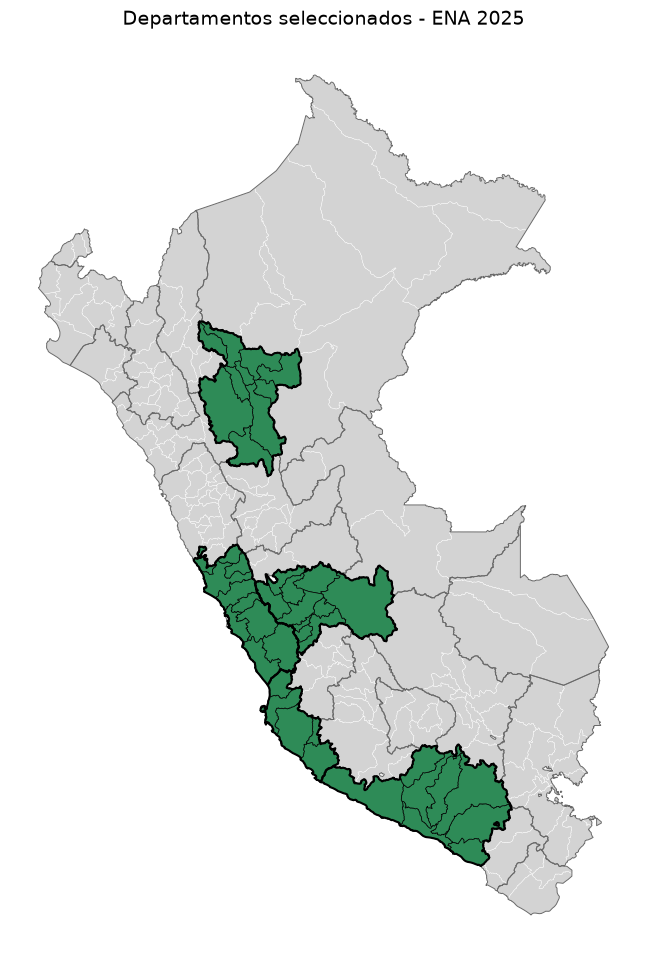

In [6]:
fig, ax = plt.subplots(figsize=(12, 12))

mapa_provincias_peru.plot(
    ax=ax,
    color="lightgray",
    edgecolor="white",
    linewidth=0.3
)

mapa_provincias.plot(
    ax=ax,
    color="seagreen",
    edgecolor="black",
    linewidth=0.5
)

mapa_departamentos_peru.boundary.plot(
    ax=ax,
    color="dimgray",
    linewidth=0.7
)

mapa_departamentos.boundary.plot(
    ax=ax,
    color="black",
    linewidth=1.5
)

ax.set_title(
    "Departamentos seleccionados - ENA 2025",
    fontsize=14
)

ax.set_axis_off()
plt.show()

# 3. Limpieza y codificación de cultivos

In [7]:
df_03_CAP200AB_limp = df_03_CAP200AB.copy()

df_03_CAP200AB_limp["NOMBREDD"] = (
    df_03_CAP200AB_limp["NOMBREDD"].str.strip().str.upper()
)

df_03_CAP200AB_limp["NOMBREPV"] = (
    df_03_CAP200AB_limp["NOMBREPV"].str.strip().str.upper()
)

df_03_CAP200AB_limp = df_03_CAP200AB_limp[
    df_03_CAP200AB_limp["NOMBREDD"].isin(departamentos)
].copy()

print("Registros originales:", len(df_03_CAP200AB))
print("Registros filtrados:", len(df_03_CAP200AB_limp))

Registros originales: 158747
Registros filtrados: 31480


In [8]:
lista_caniete = {
    "CAÃ‘ETE": "CANIETE",
    "CAÑETE": "CANIETE",
    "CAÑETE": "CANIETE"
}

mapa_provincias_peru["NOMBPROV"] = mapa_provincias_peru["NOMBPROV"].replace(lista_caniete)

mapa_provincias["NOMBPROV"] = mapa_provincias["NOMBPROV"].replace(lista_caniete)

df_03_CAP200AB_limp["NOMBREPV"] = df_03_CAP200AB_limp["NOMBREPV"].replace(lista_caniete)

print(mapa_provincias[mapa_provincias["NOMBDEP"] == "LIMA"]["NOMBPROV"].unique())
print(df_03_CAP200AB_limp[df_03_CAP200AB_limp["NOMBREDD"] == "LIMA"]["NOMBREPV"].unique())

<ArrowStringArray>
[    'HUARAL', 'HUAROCHIRI',     'HUAURA',       'LIMA',       'OYON',
     'YAUYOS',   'BARRANCA',  'CAJATAMBO',      'CANTA',    'CANIETE']
Length: 10, dtype: str
<ArrowStringArray>
[      'LIMA',   'BARRANCA',  'CAJATAMBO',      'CANTA',    'CANIETE',
     'HUARAL', 'HUAROCHIRI',     'HUAURA',       'OYON',     'YAUYOS']
Length: 10, dtype: str


In [9]:
df_03_CAP200AB_limp["P204_NOM"].value_counts()

P204_NOM
ALFALFA                        3186
PAPA BLANCA                    1662
PALTO                          1581
PLATANO                        1532
MAIZ AMILACEO                  1209
                               ... 
FRIJOL SHINGUITO GRANO SECO       1
FRIJOL HABITAS GRANO VERDE        1
PASTO CASTILLA                    1
CAÃ‘A DE AZUCAR PARA ETANOL       1
HUMARI                            1
Name: count, Length: 283, dtype: int64

In [10]:
df_03_CAP200AB_limp["cultivo"] = (
    df_03_CAP200AB_limp["P204_NOM"].fillna("").str.upper().str.strip()
)

df_03_CAP200AB_limp["cultivo"] = (
    df_03_CAP200AB_limp["cultivo"]
    .str.replace("Á", "A")
    .str.replace("É", "E")
    .str.replace("Í", "I")
    .str.replace("Ó", "O")
    .str.replace("Ú", "U")
)

df_03_CAP200AB_limp.loc[
    df_03_CAP200AB_limp["cultivo"].str.contains("FRIJOL|FREJOL"),
    "cultivo"
] = "FRIJOL"

df_03_CAP200AB_limp.loc[
    df_03_CAP200AB_limp["cultivo"].str.contains("MAIZ"),
    "cultivo"
] = "MAIZ"

df_03_CAP200AB_limp.loc[
    df_03_CAP200AB_limp["cultivo"].str.contains("HABA"),
    "cultivo"
] = "HABA"

df_03_CAP200AB_limp.loc[
    df_03_CAP200AB_limp["cultivo"].str.contains("CAFE"),
    "cultivo"
] = "CAFE"

df_03_CAP200AB_limp.loc[
    df_03_CAP200AB_limp["cultivo"].str.contains("LIMON"),
    "cultivo"
] = "LIMON"

df_03_CAP200AB_limp[["P204_NOM", "cultivo"]].drop_duplicates()

,P204_NOM,cultivo
24822,CEBOLLA,CEBOLLA
24823,LECHUGA,LECHUGA
24824,BROCOLI,BROCOLI
24826,APIO,APIO
24830,PASTO KIKUYO,PASTO KIKUYO
...,...,...
143416,COCONA,COCONA
143423,FRIJOL CHICLAYO VERDURA GRANO VERDE,FRIJOL
143429,PASTO CASTILLA,PASTO CASTILLA
143544,CAÃ‘A DE AZUCAR PARA ETANOL,CAÃ‘A DE AZUCAR PARA ETANOL


In [11]:
cultivos_seleccionados = [
    "FRIJOL", "MAIZ", "HABA",
    "ARROZ CASCARA", "PALTO",
    "PAPA AMARGA", "PAPA AMARILLA", "PAPA BLANCA",
    "PAPA COLOR", "PAPA HUAYRO", "PAPA NATIVA",
    "CAMOTE", "MANGO", "MANDARINA", "CACAO",
    "TRIGO", "CAFE", "LIMON", "NARANJO",
    "YUCA", "PLATANO", "MANZANO"
]

df_03_CAP200AB_limp = df_03_CAP200AB_limp[
    df_03_CAP200AB_limp["cultivo"].isin(cultivos_seleccionados)
].copy()

df_03_CAP200AB_limp["cultivo"].value_counts()

cultivo
MAIZ             3442
PAPA BLANCA      1662
PALTO            1581
PLATANO          1532
CAFE             1152
CACAO             898
ARROZ CASCARA     836
NARANJO           607
MANZANO           554
MANGO             496
HABA              468
LIMON             444
FRIJOL            398
MANDARINA         281
PAPA NATIVA       217
PAPA COLOR        166
TRIGO             158
CAMOTE            145
YUCA              138
PAPA AMARILLA     105
PAPA HUAYRO        73
PAPA AMARGA        20
Name: count, dtype: int64

# 4. Cálculo de duración de los cultivos

A partir del mes y año de inicio y finalización, se calcula
la duración del intervalo de cosecha registrado.

Los intervalos se clasifican en cinco categorías:

- Muy corto: 1 a 3 meses.
- Corto: 4 a 6 meses.
- Mediano: 7 a 9 meses.
- Largo: 10 a 12 meses.
- Muy largo: más de 12 meses.

In [12]:
columnas_fecha = [
    "P206_INI_MES",
    "P206_INI_ANIO",
    "P207_FIN_MES",
    "P207_FIN_ANIO"
]

for columna in columnas_fecha:
    df_03_CAP200AB_limp[columna] = pd.to_numeric(
        df_03_CAP200AB_limp[columna],
        errors="coerce"
    )

fechas_validas = (
    df_03_CAP200AB_limp["P206_INI_MES"].between(1, 12)
    & df_03_CAP200AB_limp["P207_FIN_MES"].between(1, 12)
    & df_03_CAP200AB_limp["P206_INI_ANIO"].between(1900, 2100)
    & df_03_CAP200AB_limp["P207_FIN_ANIO"].between(1900, 2100)
)

df_03_CAP200AB_limp["duracion_meses"] = (
    (df_03_CAP200AB_limp["P207_FIN_ANIO"]
     - df_03_CAP200AB_limp["P206_INI_ANIO"]) * 12
    + df_03_CAP200AB_limp["P207_FIN_MES"]
    - df_03_CAP200AB_limp["P206_INI_MES"]
    + 1
)

df_03_CAP200AB_limp.loc[
    ~fechas_validas | (df_03_CAP200AB_limp["duracion_meses"] < 1),
    "duracion_meses"
] = np.nan

df_03_CAP200AB_limp[
    ["cultivo", "P206_INI_MES", "P206_INI_ANIO",
     "P207_FIN_MES", "P207_FIN_ANIO", "duracion_meses"]
].head(10)

,cultivo,P206_INI_MES,P206_INI_ANIO,P207_FIN_MES,P207_FIN_ANIO,duracion_meses
24845,PAPA BLANCA,3,2025,3,2025,1.0
24853,PALTO,12,2024,4,2025,5.0
24855,MANZANO,1,2025,3,2025,3.0
24858,MAIZ,1,2025,1,2025,1.0
24860,MAIZ,1,2025,1,2025,1.0
24862,MAIZ,1,2025,1,2025,1.0
24864,PAPA BLANCA,3,2025,3,2025,1.0
24868,HABA,1,2025,1,2025,1.0
24869,PAPA BLANCA,12,2024,12,2024,1.0
24870,PAPA BLANCA,2,2025,2,2025,1.0


In [13]:
categorias = [
    "Muy corto",
    "Corto",
    "Mediano",
    "Largo",
    "Muy largo"
]

df_03_CAP200AB_limp["categoria_duracion"] = pd.cut(
    df_03_CAP200AB_limp["duracion_meses"],
    bins=[0, 3, 6, 9, 12, np.inf],
    labels=categorias
)

df_duracion = df_03_CAP200AB_limp.dropna(
    subset=["duracion_meses"]
).copy()

print("Registros seleccionados:", len(df_03_CAP200AB_limp))
print("Registros con duración válida:", len(df_duracion))

df_duracion[
    ["cultivo", "duracion_meses", "categoria_duracion"]
].head(10)

Registros seleccionados: 15373
Registros con duración válida: 15373


,cultivo,duracion_meses,categoria_duracion
24845,PAPA BLANCA,1.0,Muy corto
24853,PALTO,5.0,Corto
24855,MANZANO,3.0,Muy corto
24858,MAIZ,1.0,Muy corto
24860,MAIZ,1.0,Muy corto
24862,MAIZ,1.0,Muy corto
24864,PAPA BLANCA,1.0,Muy corto
24868,HABA,1.0,Muy corto
24869,PAPA BLANCA,1.0,Muy corto
24870,PAPA BLANCA,1.0,Muy corto


## Diccionario de variables

Se presenta el significado de las principales columnas utilizadas
para facilitar la comprensión del análisis.

In [14]:
diccionario_variables = pd.DataFrame({
    "Variable": [
        "NOMBREDD", "NOMBREPV", "REGION",
        "P204_NOM", "P204_COD",
        "P206_INI_MES", "P206_INI_ANIO",
        "P207_FIN_MES", "P207_FIN_ANIO",
        "cultivo", "duracion_meses", "categoria_duracion"
    ],
    "Descripción": [
        "Departamento",
        "Provincia",
        "Región natural (código)",
        "Nombre original del cultivo",
        "Código del cultivo",
        "Mes de inicio de cosecha",
        "Año de inicio de cosecha",
        "Mes de finalización de cosecha",
        "Año de finalización de cosecha",
        "Cultivo codificado",
        "Duración del intervalo en meses",
        "Categoría de duración"
    ]
})

diccionario_variables

,Variable,Descripción
0,NOMBREDD,Departamento
1,NOMBREPV,Provincia
2,REGION,Región natural (código)
3,P204_NOM,Nombre original del cultivo
4,P204_COD,Código del cultivo
5,P206_INI_MES,Mes de inicio de cosecha
6,P206_INI_ANIO,Año de inicio de cosecha
7,P207_FIN_MES,Mes de finalización de cosecha
8,P207_FIN_ANIO,Año de finalización de cosecha
9,cultivo,Cultivo codificado


## Análisis 1. Cultivos más registrados

### ¿Cuáles son los cultivos seleccionados que presentan mayor y menor cantidad de registros en los cinco departamentos?

In [15]:
tabla_01 = df_03_CAP200AB_limp.groupby("cultivo").size().reset_index(
    name="cantidad"
)

tabla_01 = tabla_01.sort_values("cantidad", ascending=False)

tabla_01["porcentaje"] = (
    tabla_01["cantidad"] / tabla_01["cantidad"].sum() * 100
).round(2)

tabla_01

,cultivo,cantidad,porcentaje
7,MAIZ,3442,22.39
15,PAPA BLANCA,1662,10.81
12,PALTO,1581,10.28
19,PLATANO,1532,9.97
2,CAFE,1152,7.49
1,CACAO,898,5.84
0,ARROZ CASCARA,836,5.44
11,NARANJO,607,3.95
10,MANZANO,554,3.60
9,MANGO,496,3.23


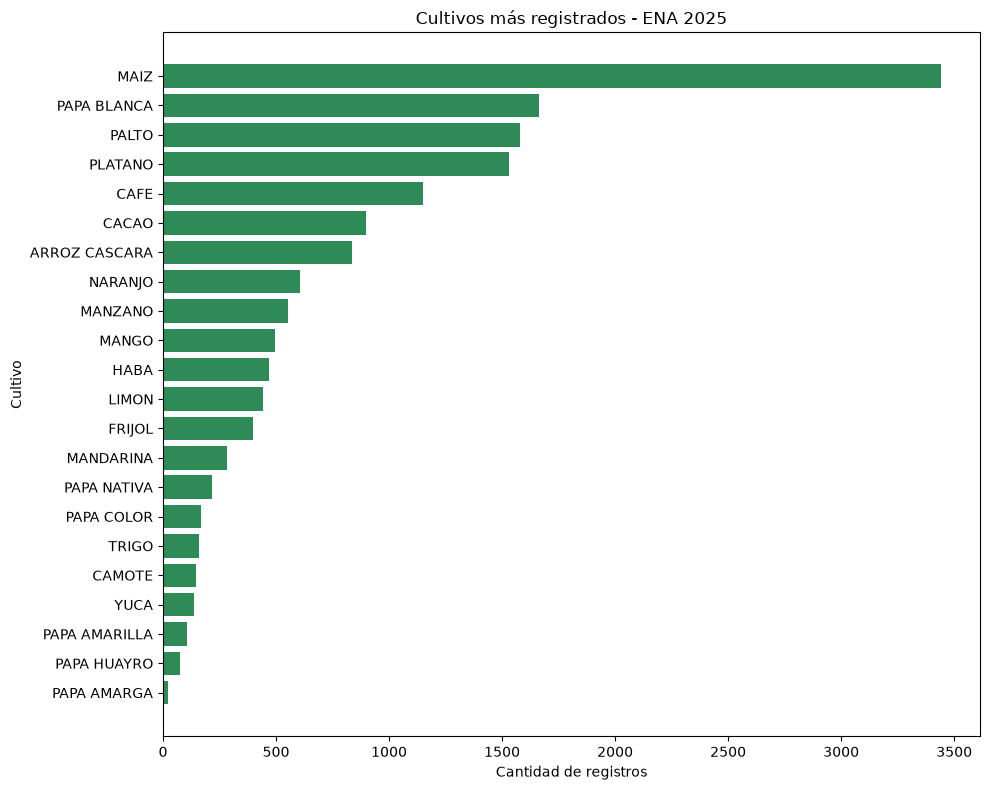

RESULTADOS GENERALES
Mayor frecuencia: MAIZ - 3442 registros
Menor frecuencia: PAPA AMARGA - 20 registros


In [16]:
plt.figure(figsize=(10, 8))

plt.barh(
    tabla_01["cultivo"],
    tabla_01["cantidad"],
    color="seagreen"
)

plt.title("Cultivos más registrados - ENA 2025")
plt.xlabel("Cantidad de registros")
plt.ylabel("Cultivo")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

mayor = tabla_01.loc[tabla_01["cantidad"].idxmax()]
menor = tabla_01.loc[tabla_01["cantidad"].idxmin()]

print("RESULTADOS GENERALES")
print(f"Mayor frecuencia: {mayor['cultivo']} - {mayor['cantidad']} registros")
print(f"Menor frecuencia: {menor['cultivo']} - {menor['cantidad']} registros")

## Análisis 2. Principales cultivos por departamento

### ¿Qué cultivos presentan mayor presencia en Lima, Ica, Arequipa, Junín y San Martín?

In [17]:
tabla_02 = pd.crosstab(
    df_03_CAP200AB_limp["cultivo"],
    df_03_CAP200AB_limp["NOMBREDD"]
)

tabla_02 = tabla_02.reindex(
    columns=departamentos,
    fill_value=0
)

tabla_02

NOMBREDD,LIMA,ICA,AREQUIPA,JUNIN,SAN MARTIN
cultivo,,,,,
ARROZ CASCARA,0,0,448,2,386
CACAO,0,0,0,213,685
CAFE,0,0,0,515,637
CAMOTE,110,18,17,0,0
FRIJOL,86,44,202,46,20
HABA,87,4,185,192,0
LIMON,83,83,164,40,74
MAIZ,620,493,1106,933,290
MANDARINA,128,28,34,23,68


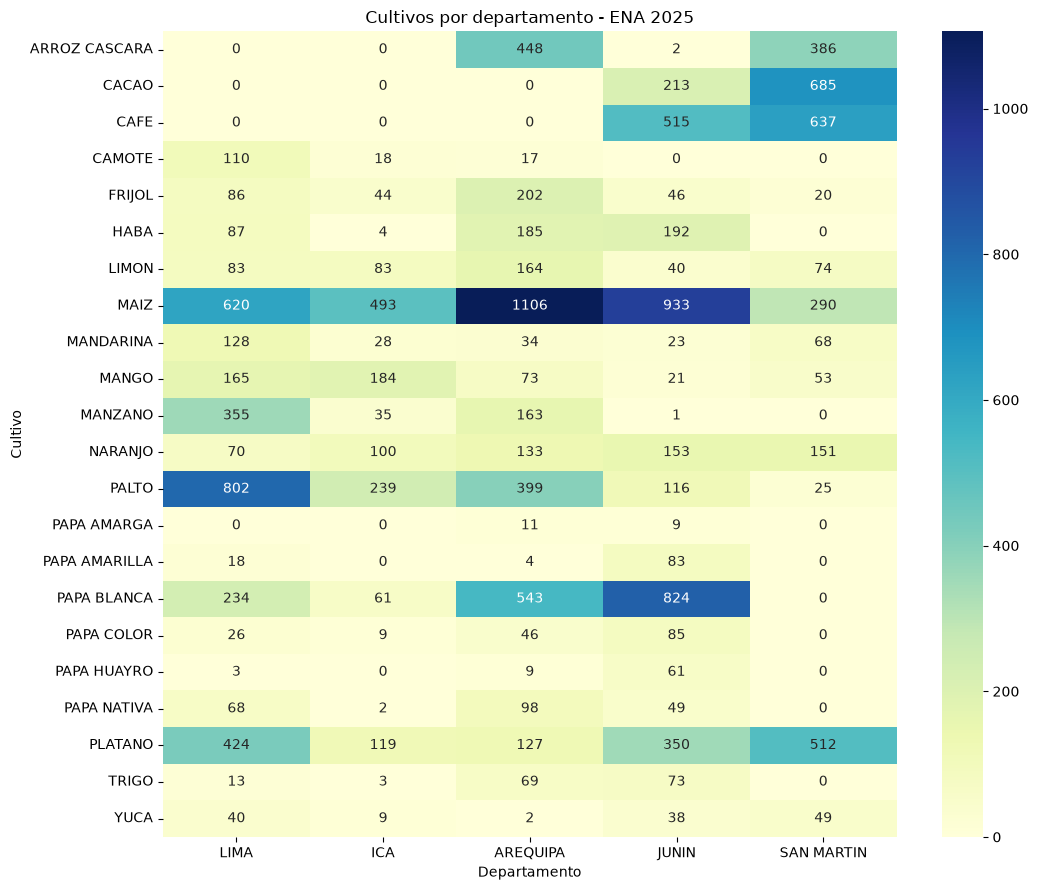

RESULTADOS POR DEPARTAMENTO
LIMA: PALTO - 802 registros
ICA: MAIZ - 493 registros
AREQUIPA: MAIZ - 1106 registros
JUNIN: MAIZ - 933 registros
SAN MARTIN: CACAO - 685 registros


In [18]:
plt.figure(figsize=(11, 9))

sns.heatmap(
    tabla_02,
    annot=True,
    fmt="d",
    cmap="YlGnBu"
)

plt.title("Cultivos por departamento - ENA 2025")
plt.xlabel("Departamento")
plt.ylabel("Cultivo")
plt.tight_layout()
plt.show()

print("RESULTADOS POR DEPARTAMENTO")

for departamento in departamentos:
    datos = tabla_02[departamento]

    if datos.sum() > 0:
        mayor = datos.idxmax()

        print(
            f"{departamento}: {mayor} - "
            f"{int(datos.max())} registros"
        )

## Análisis 3. Diversidad de cultivos por provincia

### ¿Qué provincias presentan mayor y menor cantidad de cultivos distintos entre los cultivos seleccionados?

In [19]:
reemplazos_provincias = {
    "CAÃ‘ETE": "CANETE",
    "CAÑETE": "CANETE"
}

df_03_CAP200AB_limp["NOMBREPV"] = (df_03_CAP200AB_limp["NOMBREPV"].replace(reemplazos_provincias))

mapa_provincias["NOMBPROV"] = (mapa_provincias["NOMBPROV"].replace(reemplazos_provincias))

tabla_03 = df_03_CAP200AB_limp.groupby(["NOMBREDD", "NOMBREPV"])["cultivo"].nunique().reset_index(name="cantidad_cultivos")

tabla_03 = tabla_03.sort_values(
    "cantidad_cultivos",
    ascending=False
)

tabla_03

,NOMBREDD,NOMBREPV,cantidad_cultivos
5,AREQUIPA,CONDESUYOS,18
3,AREQUIPA,CASTILLA,17
4,AREQUIPA,CAYLLOMA,16
7,AREQUIPA,LA UNION,16
16,JUNIN,HUANCAYO,16
2,AREQUIPA,CARAVELI,15
26,LIMA,HUARAL,15
27,LIMA,HUAROCHIRI,15
13,JUNIN,CHANCHAMAYO,15
8,ICA,CHINCHA,15


In [20]:
mapa_03 = mapa_provincias.merge(
    tabla_03,
    left_on=["NOMBDEP", "NOMBPROV"],
    right_on=["NOMBREDD", "NOMBREPV"],
    how="left"
).copy()

print(
    "Provincias con datos:",
    mapa_03["cantidad_cultivos"].notna().sum()
)

print(
    "Provincias sin datos:",
    mapa_03["cantidad_cultivos"].isna().sum()
)

Provincias con datos: 42
Provincias sin datos: 0


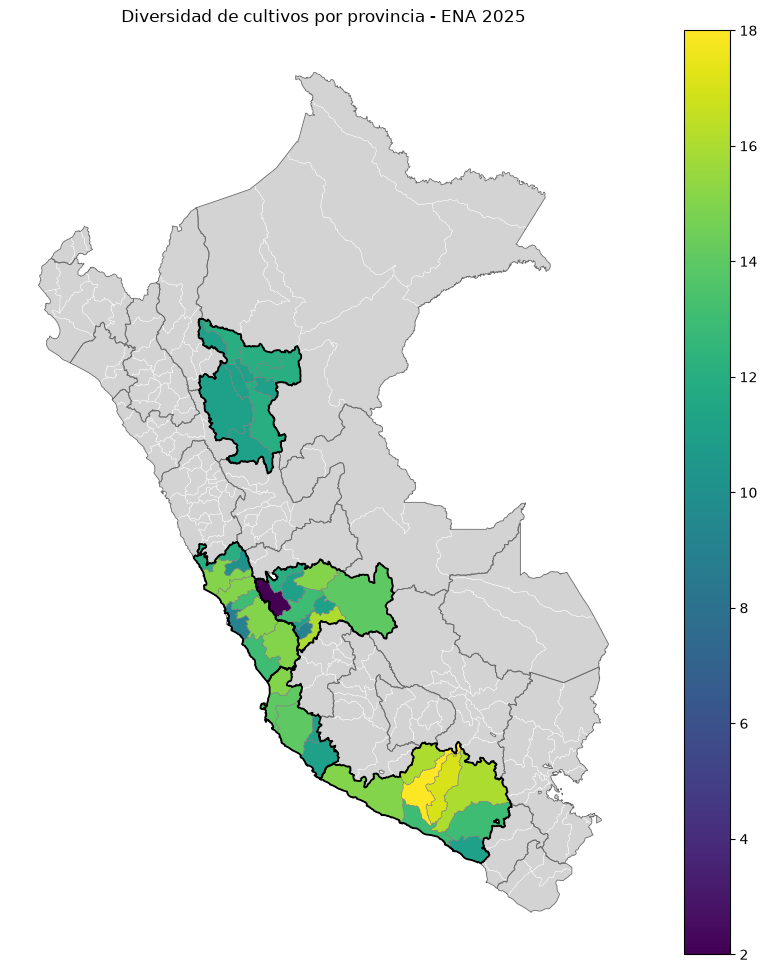

RESULTADOS GENERALES
Mayor diversidad: CONDESUYOS (AREQUIPA) - 18 cultivos
Menor diversidad: YAULI (JUNIN) - 2 cultivos


In [21]:
fig, ax = plt.subplots(figsize=(12, 12))

mapa_provincias_peru.plot(
    ax=ax,
    color="lightgray",
    edgecolor="white",
    linewidth=0.3
)

mapa_03.plot(
    column="cantidad_cultivos",
    cmap="viridis",
    legend=True,
    missing_kwds={"color": "lightgray"},
    edgecolor="gray",
    linewidth=0.4,
    ax=ax
)

mapa_departamentos_peru.boundary.plot(
    ax=ax,
    color="dimgray",
    linewidth=0.6
)

mapa_departamentos.boundary.plot(
    ax=ax,
    color="black",
    linewidth=1.3
)

ax.set_title("Diversidad de cultivos por provincia - ENA 2025")
ax.set_axis_off()

plt.show()

datos_validos = mapa_03.dropna(subset=["cantidad_cultivos"])

if len(datos_validos) > 0:
    mayor = datos_validos.loc[
        datos_validos["cantidad_cultivos"].idxmax()
    ]

    menor = datos_validos.loc[
        datos_validos["cantidad_cultivos"].idxmin()
    ]

    print("RESULTADOS GENERALES")
    print(
        f"Mayor diversidad: {mayor['NOMBPROV']} "
        f"({mayor['NOMBDEP']}) - "
        f"{int(mayor['cantidad_cultivos'])} cultivos"
    )
    print(
        f"Menor diversidad: {menor['NOMBPROV']} "
        f"({menor['NOMBDEP']}) - "
        f"{int(menor['cantidad_cultivos'])} cultivos"
    )

## Análisis 4. Clasificación de duración de los cultivos

### ¿Qué categoría de duración presenta la mayor y menor cantidad de registros?

In [22]:
tabla_04 = df_duracion["categoria_duracion"].value_counts(
    sort=False
).reset_index()

tabla_04.columns = ["categoria_duracion", "cantidad"]

tabla_04["porcentaje"] = (
    tabla_04["cantidad"] / tabla_04["cantidad"].sum() * 100
).round(2)

tabla_04

,categoria_duracion,cantidad,porcentaje
0,Muy corto,11298,73.49
1,Corto,1232,8.01
2,Mediano,29,0.19
3,Largo,2814,18.30
4,Muy largo,0,0.00


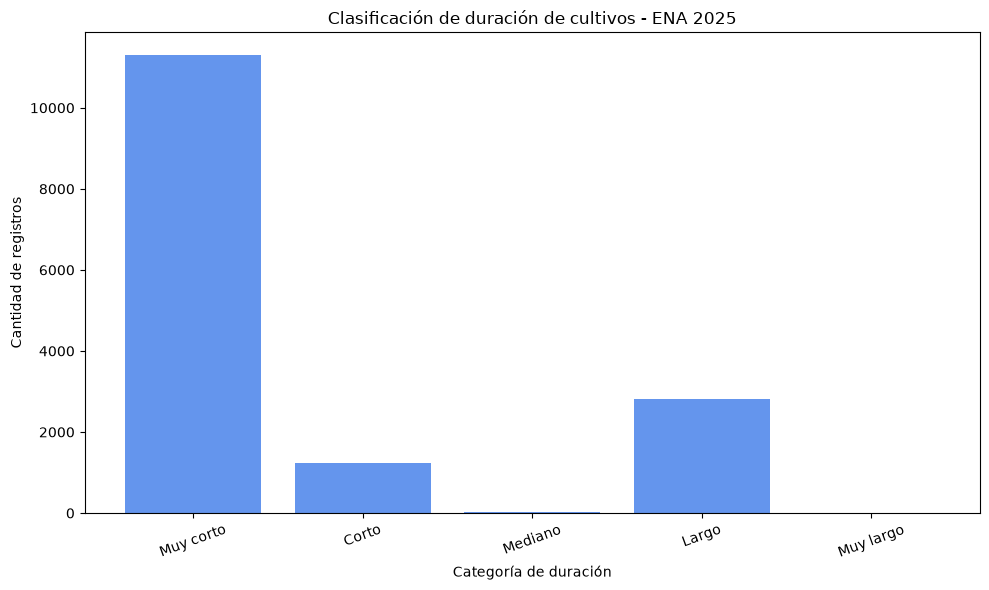

RESULTADOS GENERALES
Categoría más frecuente: Muy corto - 73.49%
Categoría menos frecuente: Muy largo - 0.0%


In [23]:
plt.figure(figsize=(10, 6))

plt.bar(
    tabla_04["categoria_duracion"].astype(str),
    tabla_04["cantidad"],
    color="cornflowerblue"
)

plt.title("Clasificación de duración de cultivos - ENA 2025")
plt.xlabel("Categoría de duración")
plt.ylabel("Cantidad de registros")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

mayor = tabla_04.loc[tabla_04["cantidad"].idxmax()]
menor = tabla_04.loc[tabla_04["cantidad"].idxmin()]

print("RESULTADOS GENERALES")
print(
    f"Categoría más frecuente: {mayor['categoria_duracion']} "
    f"- {mayor['porcentaje']}%"
)
print(
    f"Categoría menos frecuente: {menor['categoria_duracion']} "
    f"- {menor['porcentaje']}%"
)

## Análisis 5. Duración promedio por cultivo

### ¿Qué cultivos presentan el mayor y menor tiempo promedio de duración del intervalo de cosecha?

In [24]:
tabla_05 = df_duracion.groupby("cultivo")["duracion_meses"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2).reset_index()

tabla_05.columns = [
    "cultivo", "registros", "promedio",
    "mediana", "minimo", "maximo"
]

tabla_05 = tabla_05.sort_values(
    "promedio",
    ascending=False
)

tabla_05

,cultivo,registros,promedio,mediana,minimo,maximo
1,CACAO,898,12.00,12.0,12.0,12.0
19,PLATANO,1532,12.00,12.0,12.0,12.0
6,LIMON,444,10.81,12.0,1.0,12.0
2,CAFE,1152,4.01,4.0,1.0,7.0
11,NARANJO,607,2.57,2.0,1.0,7.0
12,PALTO,1581,2.37,2.0,1.0,7.0
10,MANZANO,554,2.30,2.0,1.0,7.0
8,MANDARINA,281,2.19,2.0,1.0,7.0
9,MANGO,496,2.08,2.0,1.0,5.0
5,HABA,468,1.29,1.0,1.0,2.0


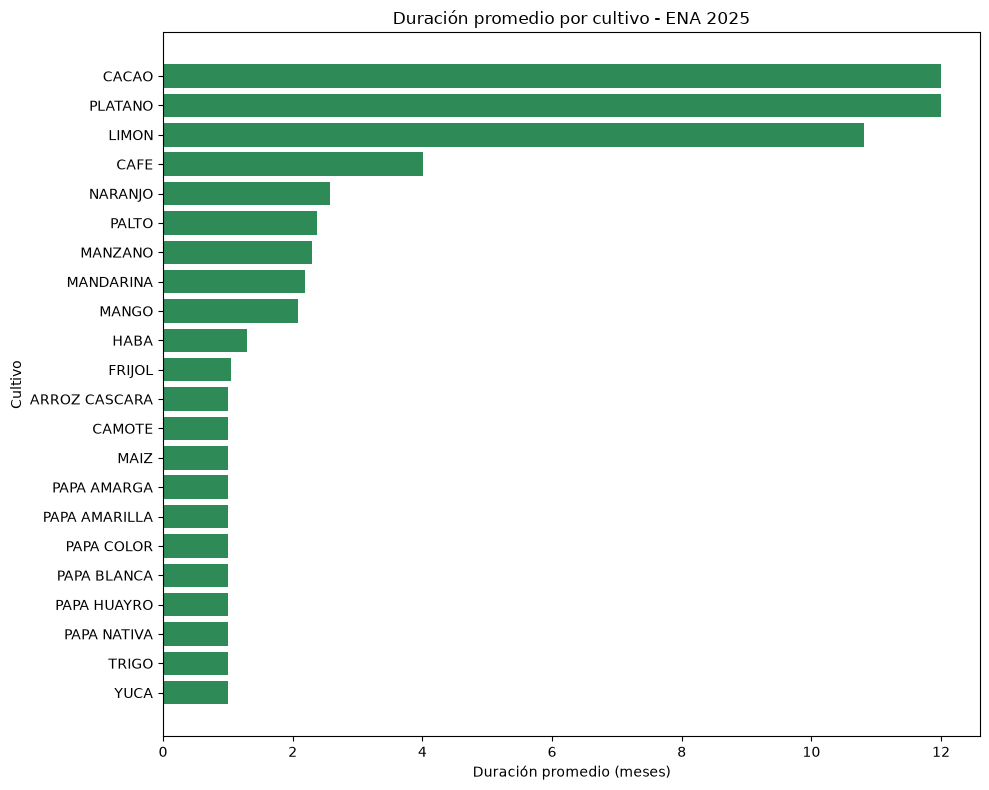

RESULTADOS GENERALES
Mayor duración promedio: CACAO - 12.0 meses
Menor duración promedio: ARROZ CASCARA - 1.0 meses


In [25]:
plt.figure(figsize=(10, 8))

plt.barh(
    tabla_05["cultivo"],
    tabla_05["promedio"],
    color="seagreen"
)

plt.title("Duración promedio por cultivo - ENA 2025")
plt.xlabel("Duración promedio (meses)")
plt.ylabel("Cultivo")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

mayor = tabla_05.loc[tabla_05["promedio"].idxmax()]
menor = tabla_05.loc[tabla_05["promedio"].idxmin()]

print("RESULTADOS GENERALES")
print(
    f"Mayor duración promedio: {mayor['cultivo']} "
    f"- {mayor['promedio']} meses"
)
print(
    f"Menor duración promedio: {menor['cultivo']} "
    f"- {menor['promedio']} meses"
)

## Análisis 6. Duración de los cultivos por departamento

### ¿Qué departamento presenta mayor y menor duración promedio de los intervalos de cosecha?

In [26]:
tabla_06 = df_duracion.groupby("NOMBREDD")["duracion_meses"].agg(
    ["count", "mean", "median", "std"]
).round(2).reset_index()

tabla_06.columns = [
    "NOMBREDD", "registros", "promedio",
    "mediana", "desviacion"
]

tabla_06 = tabla_06.sort_values(
    "promedio",
    ascending=False
)

tabla_06

,NOMBREDD,registros,promedio,mediana,desviacion
4,SAN MARTIN,2950,6.60,5.0,4.82
2,JUNIN,3827,3.21,1.0,3.88
3,LIMA,3332,3.20,2.0,3.82
1,ICA,1431,2.83,1.0,3.73
0,AREQUIPA,3833,2.17,1.0,2.87


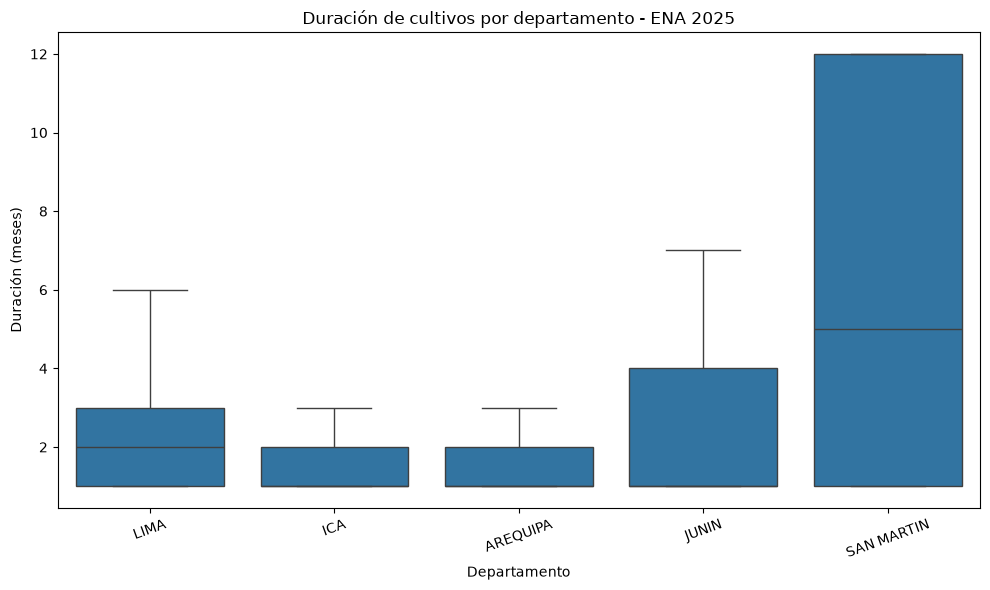

RESULTADOS GENERALES
Mayor duración promedio: SAN MARTIN - 6.6 meses
Menor duración promedio: AREQUIPA - 2.17 meses


In [27]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_duracion,
    x="NOMBREDD",
    y="duracion_meses",
    order=departamentos,
    showfliers=False
)

plt.title("Duración de cultivos por departamento - ENA 2025")
plt.xlabel("Departamento")
plt.ylabel("Duración (meses)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

mayor = tabla_06.loc[tabla_06["promedio"].idxmax()]
menor = tabla_06.loc[tabla_06["promedio"].idxmin()]

print("RESULTADOS GENERALES")
print(
    f"Mayor duración promedio: {mayor['NOMBREDD']} "
    f"- {mayor['promedio']} meses"
)
print(
    f"Menor duración promedio: {menor['NOMBREDD']} "
    f"- {menor['promedio']} meses"
)

## Análisis 7. Meses de inicio de cosecha

### ¿En qué meses se registra con mayor frecuencia el inicio del intervalo de cosecha de cada cultivo?

In [32]:
tabla_07 = pd.crosstab(
    df_duracion["cultivo"],
    df_duracion["P206_INI_MES"]
)

tabla_07 = tabla_07.reindex(
    columns=range(1, 13),
    fill_value=0
)

tabla_07

P206_INI_MES,1,2,3,4,5,6,7,8,9,10,11,12
cultivo,,,,,,,,,,,,
ARROZ CASCARA,29,107,234,174,55,25,44,34,28,32,32,42
CACAO,0,0,0,30,124,383,361,0,0,0,0,0
CAFE,70,186,428,262,165,23,11,1,0,1,2,3
CAMOTE,8,18,10,20,12,13,14,5,8,7,14,16
FRIJOL,7,18,23,30,27,28,65,86,39,42,20,13
HABA,23,26,39,45,100,138,29,15,11,10,10,22
LIMON,12,5,7,59,169,122,59,6,1,3,0,1
MAIZ,180,256,277,327,532,738,252,228,162,158,143,189
MANDARINA,25,36,23,43,55,37,20,11,8,9,9,5


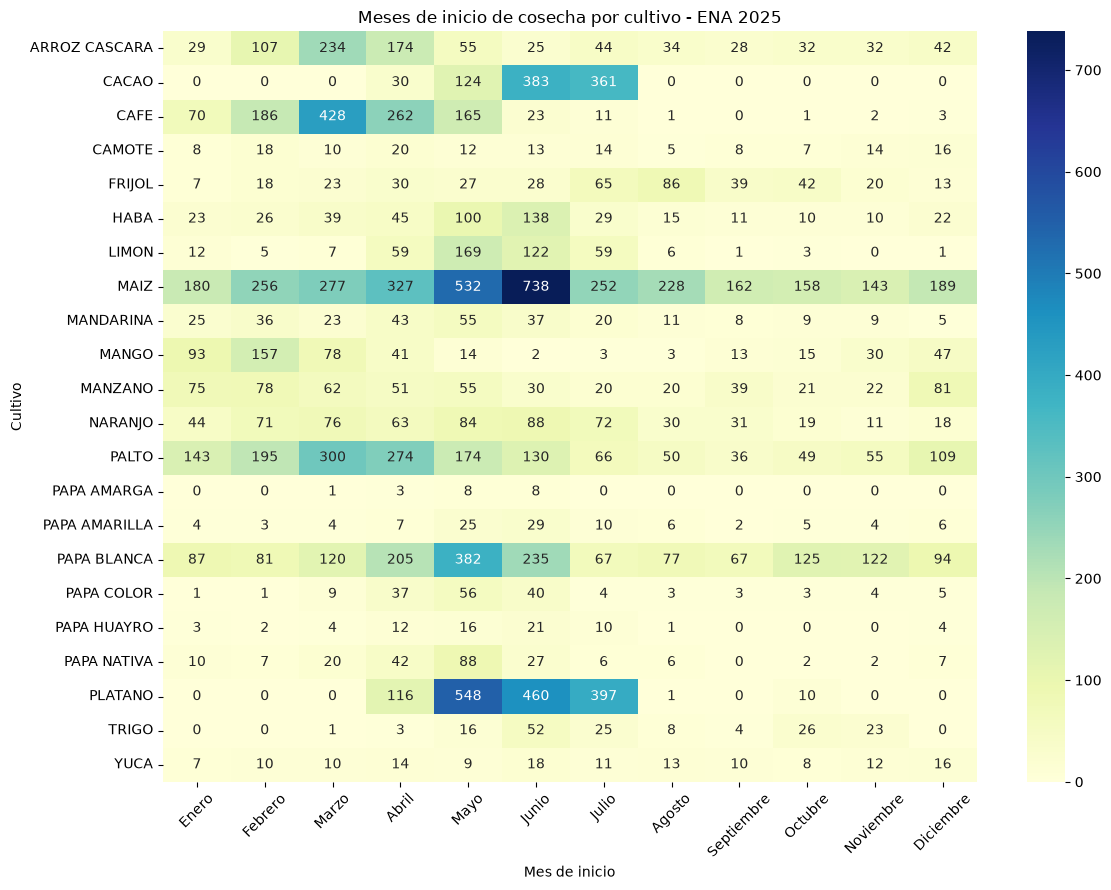

RESULTADOS GENERALES
Mes con mayor frecuencia de inicio: Mayo - 2714 registros
Mes con menor frecuencia de inicio: Septiembre - 462 registros


In [33]:
meses = [
    "Enero", "Febrero", "Marzo", "Abril",
    "Mayo", "Junio", "Julio", "Agosto",
    "Septiembre", "Octubre", "Noviembre", "Diciembre"
]

tabla_07.columns = meses

plt.figure(figsize=(12, 9))

sns.heatmap(
    tabla_07,
    annot=True,
    fmt="d",
    cmap="YlGnBu"
)

plt.title("Meses de inicio de cosecha por cultivo - ENA 2025")
plt.xlabel("Mes de inicio")
plt.ylabel("Cultivo")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

total_meses = tabla_07.sum(axis=0)

mayor_mes = total_meses.idxmax()
menor_mes = total_meses.idxmin()

print("RESULTADOS GENERALES")
print(
    f"Mes con mayor frecuencia de inicio: {mayor_mes} "
    f"- {int(total_meses.max())} registros"
)
print(
    f"Mes con menor frecuencia de inicio: {menor_mes} "
    f"- {int(total_meses.min())} registros"
)

## Análisis 8. Porcentaje de registros de frijol por provincia

### ¿Qué provincias presentan el mayor porcentaje de registros de frijol respecto al total de cultivos seleccionados de cada provincia?

In [34]:
df_08 = df_03_CAP200AB_limp[["NOMBREDD", "NOMBREPV", "cultivo"]].copy()

df_08["total_provincia"] = df_08.groupby(
    ["NOMBREDD", "NOMBREPV"]
)["cultivo"].transform("size")

tabla_08 = df_08[["NOMBREDD", "NOMBREPV", "total_provincia"]].drop_duplicates().copy()

tabla_frijol = df_08[
    df_08["cultivo"] == "FRIJOL"
].groupby(
    ["NOMBREDD", "NOMBREPV"]
).size().reset_index(name="cantidad_frijol")

tabla_08 = tabla_08.merge(
    tabla_frijol,
    on=["NOMBREDD", "NOMBREPV"],
    how="left"
)

tabla_08["cantidad_frijol"] = (tabla_08["cantidad_frijol"].fillna(0).astype(int))

tabla_08["porcentaje"] = (
    tabla_08["cantidad_frijol"] / tabla_08["total_provincia"] * 100
).round(2)

tabla_08 = tabla_08.sort_values(
    "porcentaje",
    ascending=False
)

tabla_08

,NOMBREDD,NOMBREPV,total_provincia,cantidad_frijol,porcentaje
1,AREQUIPA,CAMANA,613,187,30.51
23,LIMA,BARRANCA,428,52,12.15
13,JUNIN,HUANCAYO,631,36,5.71
10,ICA,NASCA,214,12,5.61
2,AREQUIPA,CARAVELI,172,8,4.65
12,ICA,PISCO,521,15,2.88
29,LIMA,HUAURA,422,12,2.84
8,ICA,ICA,322,9,2.80
22,LIMA,LIMA,85,2,2.35
9,ICA,CHINCHA,256,6,2.34


In [35]:
mapa_08 = mapa_provincias.merge(
    tabla_08,
    left_on=["NOMBDEP", "NOMBPROV"],
    right_on=["NOMBREDD", "NOMBREPV"],
    how="left"
).copy()

print(
    "Provincias con datos:",
    mapa_08["porcentaje"].notna().sum()
)

print(
    "Provincias sin datos:",
    mapa_08["porcentaje"].isna().sum()
)

Provincias con datos: 42
Provincias sin datos: 0


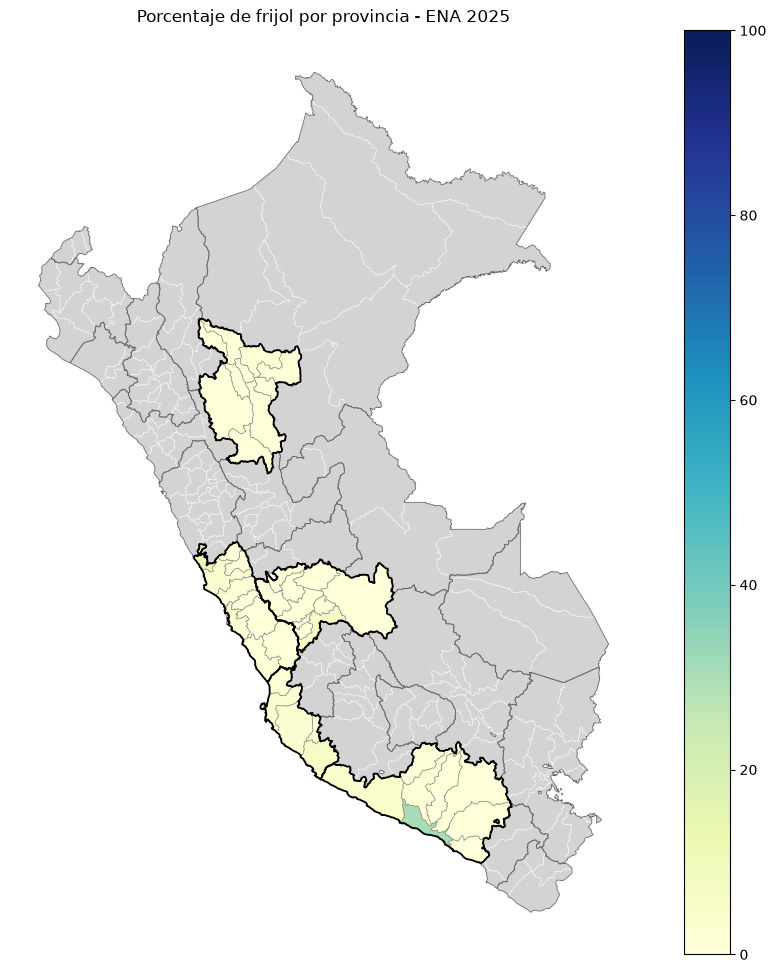

RESULTADOS GENERALES
Mayor porcentaje: CAMANA (AREQUIPA) - 30.51%
Menor porcentaje: ISLAY (AREQUIPA) - 0.0%


In [36]:
fig, ax = plt.subplots(figsize=(12, 12))

mapa_provincias_peru.plot(
    ax=ax,
    color="lightgray",
    edgecolor="white",
    linewidth=0.3
)

mapa_08.plot(
    column="porcentaje",
    cmap="YlGnBu",
    legend=True,
    missing_kwds={"color": "lightgray"},
    edgecolor="gray",
    linewidth=0.4,
    vmin=0,
    vmax=100,
    ax=ax
)

mapa_departamentos_peru.boundary.plot(
    ax=ax,
    color="dimgray",
    linewidth=0.6
)

mapa_departamentos.boundary.plot(
    ax=ax,
    color="black",
    linewidth=1.3
)

ax.set_title("Porcentaje de frijol por provincia - ENA 2025")
ax.set_axis_off()

plt.show()

datos_validos = tabla_08.dropna(subset=["porcentaje"])

if len(datos_validos) > 0:
    mayor = datos_validos.loc[
        datos_validos["porcentaje"].idxmax()
    ]

    menor = datos_validos.loc[
        datos_validos["porcentaje"].idxmin()
    ]

    print("RESULTADOS GENERALES")
    print(
        f"Mayor porcentaje: {mayor['NOMBREPV']} "
        f"({mayor['NOMBREDD']}) - {mayor['porcentaje']}%"
    )
    print(
        f"Menor porcentaje: {menor['NOMBREPV']} "
        f"({menor['NOMBREDD']}) - {menor['porcentaje']}%"
    )

## Análisis 9. Variación de la duración respecto al promedio de cada cultivo

### ¿Qué cultivos presentan mayor y menor variación en la duración de sus intervalos de cosecha?

In [37]:
df_09 = df_duracion[
    ["cultivo", "duracion_meses"]
].copy()

df_09["promedio_cultivo"] = df_09.groupby(
    "cultivo"
)["duracion_meses"].transform("mean")

df_09["diferencia"] = (
    df_09["duracion_meses"] - df_09["promedio_cultivo"]
).abs()

tabla_09 = df_09.groupby("cultivo").agg(
    registros=("duracion_meses", "count"),
    promedio=("duracion_meses", "mean"),
    variacion=("diferencia", "mean")
).round(2).reset_index()

tabla_09 = tabla_09.sort_values(
    "variacion",
    ascending=False
)

tabla_09

,cultivo,registros,promedio,variacion
6,LIMON,444,10.81,2.05
11,NARANJO,607,2.57,0.96
12,PALTO,1581,2.37,0.91
10,MANZANO,554,2.30,0.91
2,CAFE,1152,4.01,0.78
8,MANDARINA,281,2.19,0.74
9,MANGO,496,2.08,0.63
5,HABA,468,1.29,0.41
4,FRIJOL,398,1.05,0.10
0,ARROZ CASCARA,836,1.00,0.00


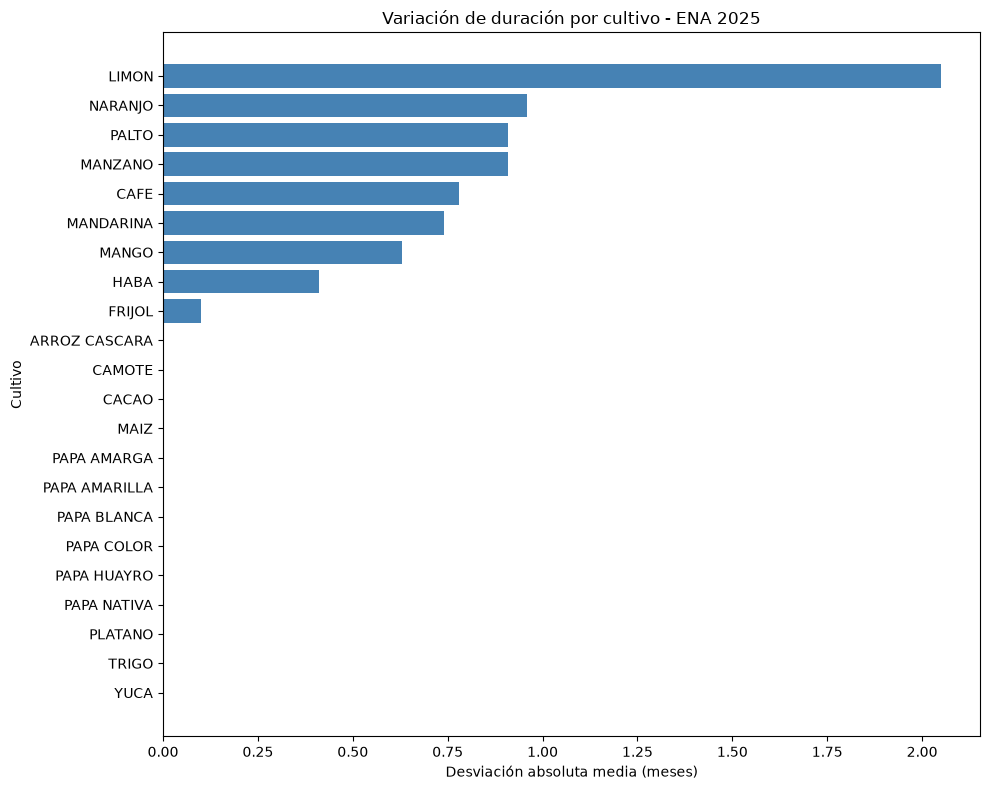

RESULTADOS GENERALES
Mayor variación: LIMON - 2.05 meses
Menor variación: ARROZ CASCARA - 0.0 meses


In [38]:
plt.figure(figsize=(10, 8))

plt.barh(
    tabla_09["cultivo"],
    tabla_09["variacion"],
    color="steelblue"
)

plt.title("Variación de duración por cultivo - ENA 2025")
plt.xlabel("Desviación absoluta media (meses)")
plt.ylabel("Cultivo")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

mayor = tabla_09.loc[tabla_09["variacion"].idxmax()]
menor = tabla_09.loc[tabla_09["variacion"].idxmin()]

print("RESULTADOS GENERALES")
print(
    f"Mayor variación: {mayor['cultivo']} "
    f"- {mayor['variacion']} meses"
)
print(
    f"Menor variación: {menor['cultivo']} "
    f"- {menor['variacion']} meses"
)

## Análisis 10. Participación porcentual de cultivos por departamento

### ¿Qué cultivos representan el mayor porcentaje de registros dentro de cada departamento?

In [39]:
df_10 = df_03_CAP200AB_limp[
    ["NOMBREDD", "cultivo"]
].copy()

df_10["total_departamento"] = df_10.groupby(
    "NOMBREDD"
)["cultivo"].transform("size")

tabla_10 = df_10.groupby(
    ["NOMBREDD", "cultivo"]
).agg(
    cantidad=("cultivo", "size"),
    total_departamento=("total_departamento", "first")
).reset_index()

tabla_10["porcentaje"] = (
    tabla_10["cantidad"]
    / tabla_10["total_departamento"] * 100
).round(2)

tabla_10 = tabla_10.sort_values(
    ["NOMBREDD", "porcentaje"],
    ascending=[True, False]
)

tabla_10

,NOMBREDD,cultivo,cantidad,total_departamento,porcentaje
5,AREQUIPA,MAIZ,1106,3833,28.85
13,AREQUIPA,PAPA BLANCA,543,3833,14.17
0,AREQUIPA,ARROZ CASCARA,448,3833,11.69
10,AREQUIPA,PALTO,399,3833,10.41
2,AREQUIPA,FRIJOL,202,3833,5.27
...,...,...,...,...,...
81,SAN MARTIN,MANDARINA,68,2950,2.31
82,SAN MARTIN,MANGO,53,2950,1.80
86,SAN MARTIN,YUCA,49,2950,1.66
84,SAN MARTIN,PALTO,25,2950,0.85


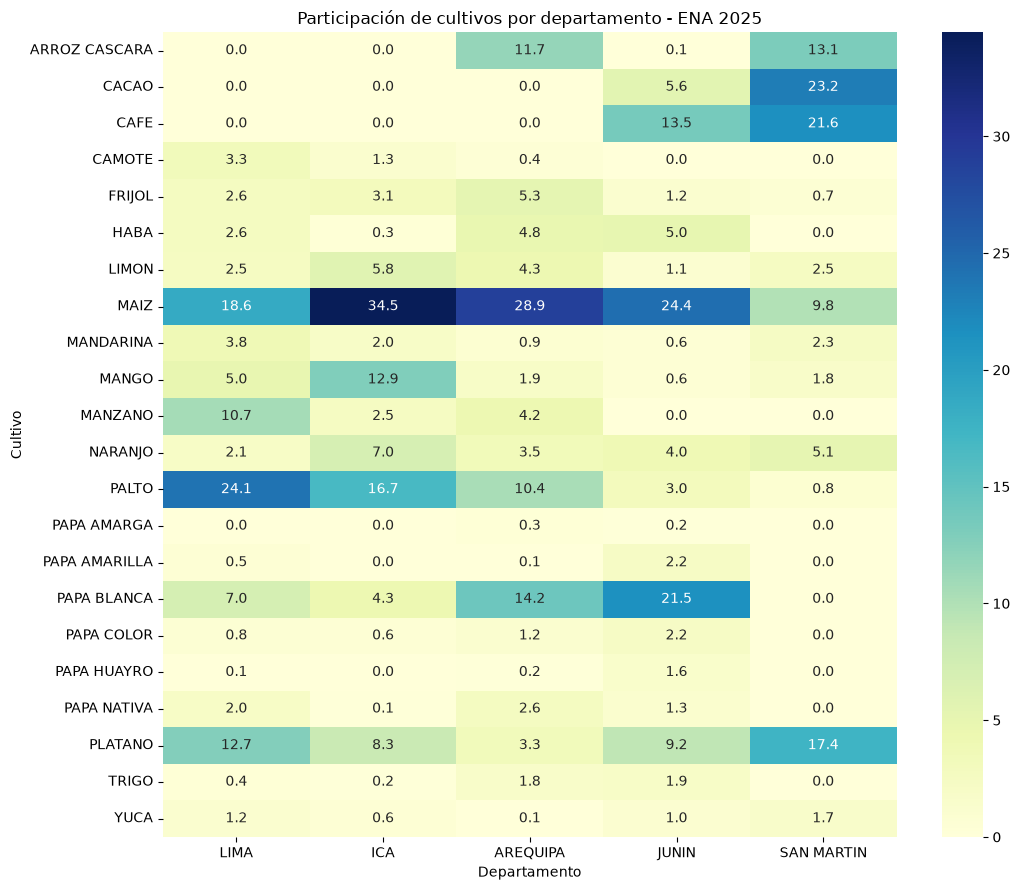

RESULTADOS POR DEPARTAMENTO
LIMA: PALTO - 24.07%
ICA: MAIZ - 34.45%
AREQUIPA: MAIZ - 28.85%
JUNIN: MAIZ - 24.38%
SAN MARTIN: CACAO - 23.22%


In [40]:
tabla_10_grafico = tabla_10.pivot(
    index="cultivo",
    columns="NOMBREDD",
    values="porcentaje"
).fillna(0)

tabla_10_grafico = tabla_10_grafico.reindex(
    columns=departamentos,
    fill_value=0
)

plt.figure(figsize=(11, 9))

sns.heatmap(
    tabla_10_grafico,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu"
)

plt.title("Participación de cultivos por departamento - ENA 2025")
plt.xlabel("Departamento")
plt.ylabel("Cultivo")
plt.tight_layout()
plt.show()

print("RESULTADOS POR DEPARTAMENTO")

for departamento in departamentos:
    datos = tabla_10[
        tabla_10["NOMBREDD"] == departamento
    ]

    if len(datos) > 0:
        mayor = datos.loc[datos["porcentaje"].idxmax()]

        print(
            f"{departamento}: {mayor['cultivo']} "
            f"- {mayor['porcentaje']}%"
        )